In [ ]:
import torch
import lab07_lib as L

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0))
print("Устройство:", L.DEVICE)
print("Наборы сцен:", L.KINDS)

PyTorch: 2.11.0+cu130
GPU: Tesla T4
Устройство: cuda
Наборы сцен: ['disc', 'disc_rect', 'disc_noise', 'disc_color', 'two_discs']


In [ ]:
N = 22

c = (N - 1) // 6
k = (N - 1) % 6

kind = L.KINDS[c]
factor = L.FACTORS[k]

a_cfg, b_cfg = L.settings(factor)

print("Вариант:", N)
print("Набор сцен:", kind)
print("Фактор:", factor)
print()
print("Условие A:", a_cfg)
print("Условие B:", b_cfg)
print("Seed:", list(L.SEEDS))

Вариант: 22
Набор сцен: disc_color
Фактор: loss_mse_to_l1

Условие A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
Условие B: {'arch': 'conv', 'd': 8, 'loss': 'l1', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
Seed: [101, 102, 103, 104, 105]


In [ ]:
result = L.variant_summary(22)

print("Вариант:", result["variant"])
print("Набор сцен:", L.KINDS[result["ctx"] - 1])
print("Фактор:", result["factor"])

print("\nРезультаты:")
for name, a, s, b, d, q, sig in result["rows"]:
    print(
        f"{name:8s} "
        f"A={a:8.3f} "
        f"s={s:6.3f} "
        f"B={b:8.3f} "
        f"Δ={d:+8.3f} "
        f"|Δ|/s={q:7.2f} "
        f"2s={'да' if sig else 'нет'}"
    )

Вариант: 22
Набор сцен: disc_color
Фактор: loss_mse_to_l1

Результаты:
psnr     A=  21.176 s= 1.006 B=  17.793 Δ=  -3.383 |Δ|/s=   3.36 2s=да
gap      A=   0.101 s= 0.034 B=   0.064 Δ=  -0.036 |Δ|/s=   1.07 2s=нет
params   A= 101.035 s= 0.000 B= 101.035 Δ=  +0.000 |Δ|/s=    inf 2s=нет
seconds  A=   1.717 s= 0.041 B=   1.683 Δ=  -0.035 |Δ|/s=   0.84 2s=нет


In [ ]:
Xtr, Xte, Ftr, Fte = L.dataset(kind)

mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
baseline_psnr = L.psnr_images(mean_image, Xte)

print("Эталон «средняя картинка»:", round(baseline_psnr, 3), "дБ")

for name, a, s, b, d, q, sig in result["rows"]:
    if name == "psnr":
        print("Превышение эталона, MSE:", round(a - baseline_psnr, 3), "дБ")
        print("Превышение эталона, L1:", round(b - baseline_psnr, 3), "дБ")

Эталон «средняя картинка»: 18.12 дБ
Превышение эталона, MSE: 3.056 дБ
Превышение эталона, L1: -0.327 дБ


Первая строка — оригиналы
Вторая строка — MSE
Третья строка — L1


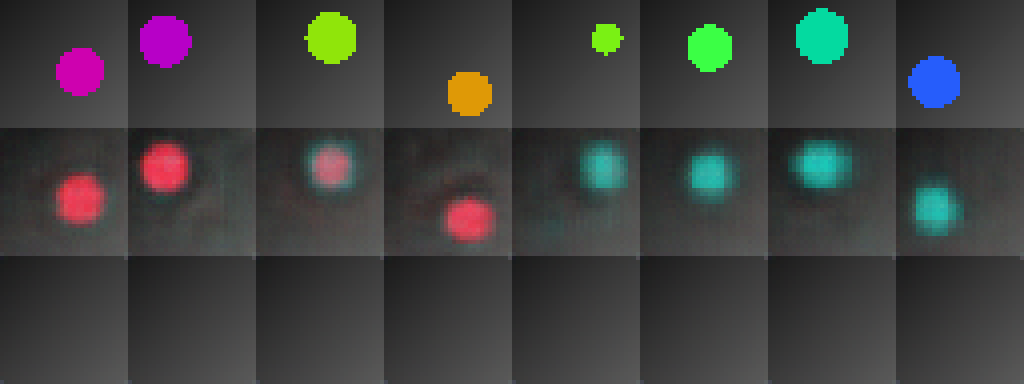

In [ ]:
import numpy as np
from PIL import Image
from IPython.display import display

# Первые 8 изображений тестовой выборки
rows = [Xte[:8]]

# Обучаем модели с seed=101
for cfg in (a_cfg, b_cfg):
    model = L.run(kind, cfg, 101)[1]
    reconstructed = L.reconstruct(
        model,
        Xte[:8],
        cfg["eval_noise"]
    )
    rows.append(reconstructed)

# Собираем сравнительный лист
grid = np.concatenate([
    np.concatenate(
        list(r.permute(0, 2, 3, 1).cpu().numpy()),
        axis=1
    )
    for r in rows
], axis=0)

comparison = Image.fromarray(
    (grid * 255).round().astype("uint8")
).resize((1024, 384), Image.Resampling.NEAREST)

comparison.save("comparison.png")

print("Первая строка — оригиналы")
print("Вторая строка — MSE")
print("Третья строка — L1")

display(comparison)

In [ ]:
import numpy as np

for d in (1, 2, 3, 4, 8):
    vals = [
        L.run(
            kind,
            dict(L.BASE, d=d),
            seed
        )[0]["psnr"]
        for seed in (101, 102, 103)
    ]

    print(
        f"d={d}: PSNR = {np.mean(vals):.2f} дБ "
        f"(seed: {', '.join(f'{v:.2f}' for v in vals)})"
    )

d=1: PSNR = 18.80 дБ (seed: 18.86, 18.78, 18.75)
d=2: PSNR = 19.21 дБ (seed: 19.21, 19.21, 19.21)
d=3: PSNR = 20.00 дБ (seed: 19.33, 21.28, 19.39)
d=4: PSNR = 20.45 дБ (seed: 20.62, 19.41, 21.33)
d=8: PSNR = 21.39 дБ (seed: 21.41, 21.84, 20.93)


In [ ]:
import pandas as pd

columns = [
    "metric", "mean_A", "sd_A", "mean_B",
    "delta", "delta_over_sd", "above_2sd"
]

df = pd.DataFrame(result["rows"], columns=columns)
df.to_csv("results.csv", index=False)

print("results.csv сохранён")
display(df.round(4))

results.csv сохранён


,metric,mean_A,sd_A,mean_B,delta,delta_over_sd,above_2sd
0,psnr,21.1763,1.0064,17.7932,-3.3830,3.3617,True
1,gap,0.1007,0.0337,0.0644,-0.0363,1.0744,False
2,params,101.0350,0.0000,101.0350,0.0000,inf,False
3,seconds,1.7173,0.0411,1.6826,-0.0346,0.8414,False
